AMATH 582 - W2026 - Bamdad Hosseini

The following code helps you visualize the submarine data and contains the crucial information about the data such as size of measurement domain, number of grid points and frequency modes etc. 

Three files are available, "subdata.npy" is a numpy binary file most conveninet for Python users. "subtata.mat" is best if you plan to use MATLAB and "subdata.csv" is the same data in text format if you are having trouble with the other formats. In MATLAB you can simply use the load command. In Python, and in particular if you are using something like Colab you need some utilities to load the data. Here's a small snippet for loading data from your Google drive.   

In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# show where Python is running (helpful for debugging)
print("Current working directory:", Path.cwd())

# construct path to file in same folder as the notebook's working directory
data_path = Path.cwd() / "subdata.npy"

#data_path = '/YOUR PATH/subdata.npy'

d = np.load(data_path) # huge matrix of size 262144 x 49 (columns contain flattened 3d matrix of size 64x64x64)
print(d.shape)
print(d[:, 0])
n=(np.cbrt(d.shape[0])).astype(int)
T=d.shape[1]

Current working directory: /Users/parthasarathykrishnamurthy/Documents/AMATH/Computational-method-data-analysis/hw1
(262144, 49)
[-0.18426731 -0.21532552  0.27324244 ...  0.48921441  0.04544374
  0.34368159]


In [43]:
def plot_3D(path, title, save_plot=False):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    time_steps = np.arange(len(path))
    ax.plot(path[:,0], path[:,1], path[:,2], color='gray', alpha=0.4, linewidth=1)
    sc = ax.scatter(path[:,0], path[:,1], path[:,2], c=time_steps, cmap='viridis', s=40)
    ax.scatter(path[0,0], path[0,1], path[0,2], color='green', s=150, marker='^', label='Start (t=0)')
    ax.scatter(path[-1,0], path[-1,1], path[-1,2], color='red', s=150, marker='X', label='End (t=48)')
    n = 64
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_zlim(0, n)
    ax.set_title(title)
    ax.set_xlabel("X Index")
    ax.set_ylabel("Y Index")
    ax.set_zlabel("Z Index")
    cbar = plt.colorbar(sc, ax=ax, shrink=0.5, pad=0.1)
    cbar.set_label('Time Step (0-48)')
    ax.view_init(elev=20, azim=45) 
    plt.legend()
    if save_plot:
        plt.savefig('plot_3D.pdf', format='pdf', bbox_inches='tight')
    plt.show()

def plot_2D(path, title, save_plot=False):
    plt.figure(figsize=(6, 6))
    plt.plot(path[:, 0], path[:, 1], '-o', label='Submarine Path', color='b')
    plt.plot(path[0, 0], path[0, 1], 'g^', markersize=10, label='Start (t=0)')
    plt.plot(path[-1, 0], path[-1, 1], 'rx', markersize=10, label='End (t=48)')
    plt.title(title)
    plt.xlabel("X Grid Index")
    plt.ylabel("Y Grid Index")
    plt.legend()
    plt.grid(True)
    plt.xlim(0, n)
    plt.ylim(0, n)
    if save_plot:
        plt.savefig('plot_2D.pdf', format='pdf', bbox_inches='tight')
    plt.show()

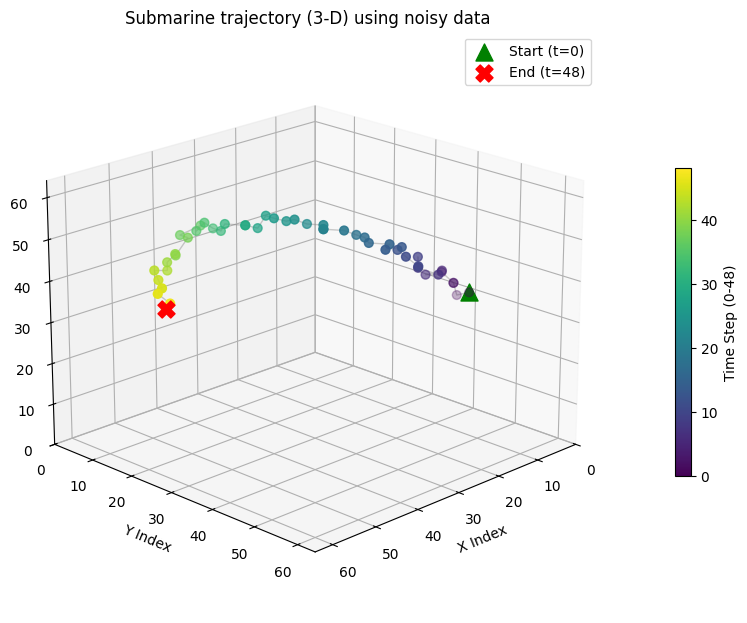

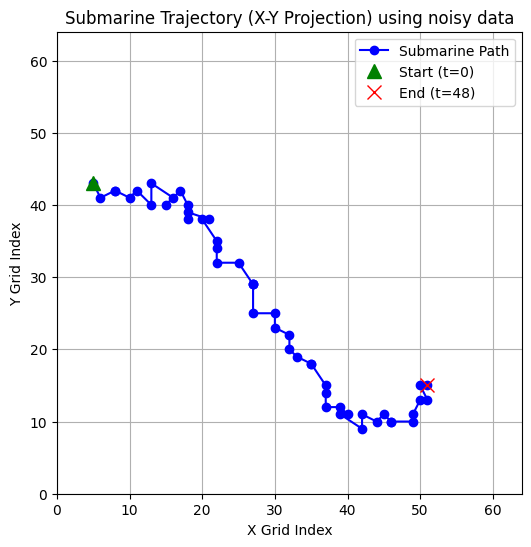

In [3]:
def trace_path_raw_data():
    coords = np.empty((T, 3), dtype=int)
    coords_2D = np.empty((T, 2), dtype=int)
    for j in range(T):
        current_d = d[:, j]
        reshaped_current_d = current_d.reshape(n, n, n)
        flat_idx = np.argmax(np.abs(reshaped_current_d))
        coord = np.unravel_index(flat_idx, reshaped_current_d.shape)
        coords[j] = coord
        coords_2D[j] = [coord[0], coord[1]]
    plot_3D(coords, "Submarine trajectory (3-D) using noisy data")
    plot_2D(coords_2D, "Submarine Trajectory (X-Y Projection) using noisy data")
trace_path_raw_data()

Frequency Signature found at index: [25 15 53]


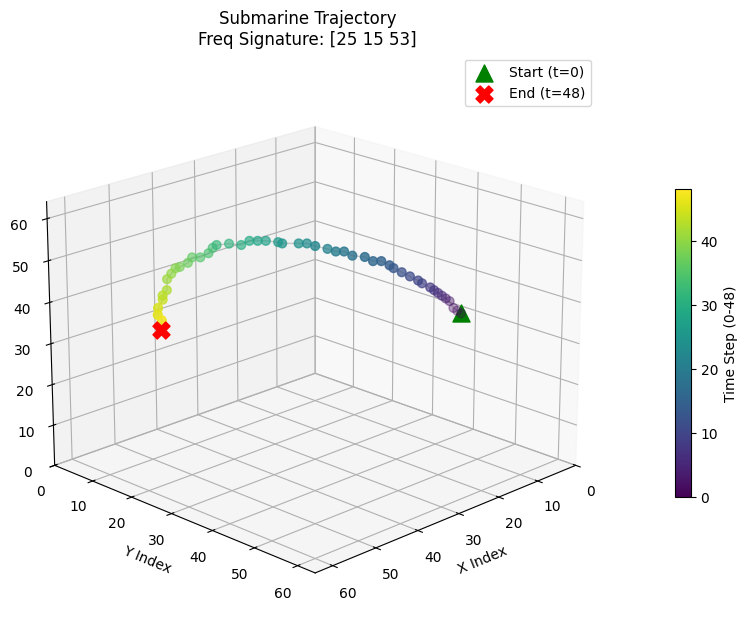

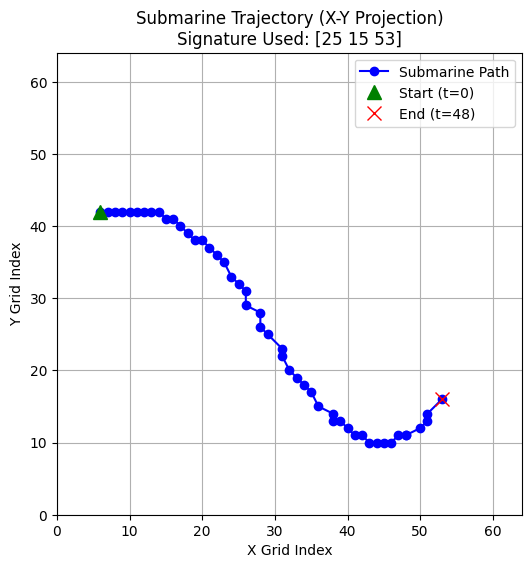

In [53]:
def frequency_signature():
    avg_spectrum = np.zeros((n, n, n))
    for j in range(T):
        vol = d[:, j].reshape(n, n, n)
        f = np.fft.fftshift(np.fft.fftn(vol))
        avg_spectrum += np.abs(f)
    flat_idx = np.argmax(avg_spectrum)
    sig_kx, sig_ky, sig_kz = np.unravel_index(flat_idx, (n, n, n))
    signature = np.array([sig_kx, sig_ky, sig_kz])
    print(f"Frequency Signature found at index: {signature}")
    return signature

def get_gaussian_mask(shape, center_coords, sigma=3.0):
    x, y, z = np.ogrid[:shape[0], :shape[1], :shape[2]]
    dist_sq = (x - center_coords[0])**2 + (y - center_coords[1])**2 + (z - center_coords[2])**2
    return np.exp(-dist_sq / (2 * sigma**2))

def trace_path_denoising(signature):
    mask = get_gaussian_mask((n,n,n), signature)
    path = np.zeros((T, 3))
    path_2d = np.zeros((T, 2))
    
    for j in range(T):
        vol = d[:, j].reshape(n, n, n)
        f = np.fft.fftshift(np.fft.fftn(vol))
        f_filtered = f * mask
        spatial_clean = np.fft.ifftn(np.fft.ifftshift(f_filtered))
        flat_idx = np.argmax(np.abs(spatial_clean))
        coords = np.unravel_index(flat_idx, (n, n, n))
        path[j] = coords
        path_2d[j] = [coords[0], coords[1]]
    
    plot_3D(path, f"Submarine Trajectory\nFreq Signature: {signature}", True)
    plot_2D(path_2d, f"Submarine Trajectory (X-Y Projection)\nSignature Used: {signature}", True)

trace_path_denoising(frequency_signature())

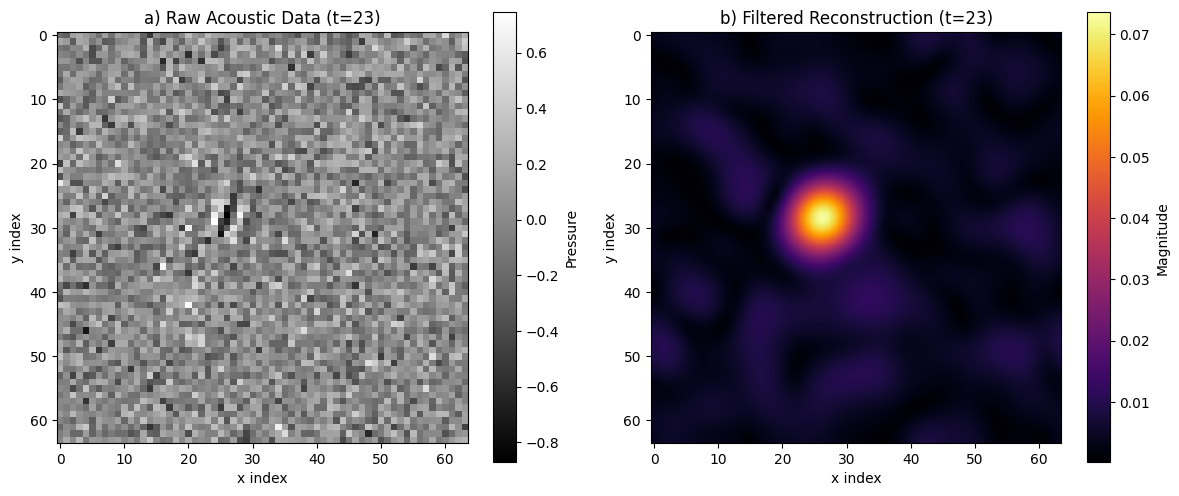

In [54]:
def compare_raw_filtered():
    t_idx = 23
    raw_vol = d[:, t_idx].reshape(n, n, n)
    fft_frame = np.fft.fftshift(np.fft.fftn(raw_vol))
    fft_filtered = fft_frame * mask 
    spatial_clean = np.fft.ifftn(np.fft.ifftshift(fft_filtered))
    clean_vol = np.abs(spatial_clean)
    z_layer = np.argmax(np.max(clean_vol, axis=(0, 1)))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    im1 = ax1.imshow(raw_vol[:, :, z_layer].real, cmap='gray', interpolation='nearest')
    ax1.set_title(f"a) Raw Acoustic Data (t={t_idx})")
    ax1.set_xlabel("x index")
    ax1.set_ylabel("y index")
    plt.colorbar(im1, ax=ax1, label="Pressure")
    im2 = ax2.imshow(clean_vol[:, :, z_layer], cmap='inferno', interpolation='gaussian')
    ax2.set_title(f"b) Filtered Reconstruction (t={t_idx})")
    ax2.set_xlabel("x index")
    ax2.set_ylabel("y index")
    plt.colorbar(im2, ax=ax2, label="Magnitude")
    plt.tight_layout()
    plt.savefig("filter_reconstruction.pdf", dpi=300) # Save for your report
    plt.show()
compare_raw_filtered()

In [37]:
#25, 15, 53
def freq(d, n):
    return d * (2*np.pi / n)
freq(53, 64)

5.203262832508095

In [5]:
#pip install plotly # in case you don't have it installed.

In [ ]:
# import libraries for plotting isosurfaces
import plotly
import plotly.graph_objs as go
# utility for clearing output of cell as loop runs in notebook
from IPython.display import clear_output
import plotly.io as pio
pio.renderers.default = "notebook"

# plot the data in time 

L = 10; # length of spatial domain (cube of side L = 2*10)
N_grid = 64; # number of grid points/Fourier modes in each direction
xx = np.linspace(-L, L, N_grid+1) #spatial grid in x dir
x = xx[0:N_grid]
y = x # same grid in y,z direction
z = x

K_grid = (2*np.pi/(2*L))*np.linspace(-N_grid/2, N_grid/2 -1, N_grid) # frequency grid for one coordinate

xv, yv, zv = np.meshgrid( x, y, z) # generate 3D meshgrid for plotting

# plot iso surfaces for every third measurement

for j in range(0,49,3):

  signal = np.reshape(d[:, j], (N_grid, N_grid, N_grid))
  normal_sig_abs = np.abs(signal)/np.abs(signal).max()

  # generate data for isosurface of the 3D data 
  fig_data = go.Isosurface( x = xv.flatten(), y = yv.flatten(), z = zv.flatten(),
                           value = normal_sig_abs.flatten(), isomin=0.7, isomax=0.7)

  # generate plots
  clear_output(wait=True) # need this to discard previous figs
  fig = go.Figure( data = fig_data )
  fig.show()
